In [1]:
# Execute the write cell content directly to generate the data files
import numpy as np, pandas as pd

rng = np.random.default_rng(55)
n = 1200
students = pd.DataFrame({
    "student_id": range(1, n + 1),
    "county": rng.choice(["Nairobi", "Kisumu", "Nakuru",
                          "Mombasa", "Nyeri", "Turkana"], n),
    "school_type": rng.choice(["Public", "Private"], n, p=[0.75, 0.25]),
    "gender": rng.choice(["F", "M"], n),
    "attendance_rate": rng.beta(8, 2, n).round(2),
    "study_hours": rng.gamma(2.5, 2.0, n).round(1),
})
base = (35 + 30 * students["attendance_rate"] + 2.2 * students["study_hours"]
        + np.where(students["school_type"] == "Private", 6, 0))
students["math"] = (base + rng.normal(0, 8, n)).clip(0, 100).round(0)
students["english"] = (base + rng.normal(3, 7, n)).clip(0, 100).round(0)
students["science"] = (base + rng.normal(-2, 9, n)).clip(0, 100).round(0)
students.to_csv("student_performance.csv", index=False)

rng = np.random.default_rng(2026)
n = 1000
products = {"Phone": 15000, "Laptop": 65000, "Headphones": 2500,
            "Tablet": 28000, "Charger": 1200}

sales = pd.DataFrame({
    "order_id": range(1001, 1001 + n),
    "order_date": pd.to_datetime("2026-01-01")
                  + pd.to_timedelta(rng.integers(0, 180, n), unit="D"),
    "branch": rng.choice(["Nairobi", "Mombasa", "Kisumu", "Nakuru", "Eldoret"], n,
                         p=[0.4, 0.2, 0.15, 0.15, 0.1]),
    "product": rng.choice(list(products), n),
    "quantity": rng.integers(1, 6, n),
    "channel": rng.choice(["In-store", "Online", "Phone order"], n,
                          p=[0.55, 0.35, 0.10]),
})
sales["unit_price"] = sales["product"].map(products)
sales.to_csv("duka_sales.csv", index=False)
print("Data generated successfully!")

Data generated successfully!


In [2]:
%%writefile generate_data.py
# ============================================================
# Engagement 1: Student performance generator (seed 55)
# ============================================================
import numpy as np, pandas as pd

rng = np.random.default_rng(55)
n = 1200
students = pd.DataFrame({
    "student_id": range(1, n + 1),
    "county": rng.choice(["Nairobi", "Kisumu", "Nakuru",
                          "Mombasa", "Nyeri", "Turkana"], n),
    "school_type": rng.choice(["Public", "Private"], n, p=[0.75, 0.25]),
    "gender": rng.choice(["F", "M"], n),
    "attendance_rate": rng.beta(8, 2, n).round(2),
    "study_hours": rng.gamma(2.5, 2.0, n).round(1),
})
base = (35 + 30 * students["attendance_rate"] + 2.2 * students["study_hours"]
        + np.where(students["school_type"] == "Private", 6, 0))
students["math"] = (base + rng.normal(0, 8, n)).clip(0, 100).round(0)
students["english"] = (base + rng.normal(3, 7, n)).clip(0, 100).round(0)
students["science"] = (base + rng.normal(-2, 9, n)).clip(0, 100).round(0)
students.to_csv("student_performance.csv", index=False)


# ============================================================
# Engagement 2: Duka Electronics generator (seed 2026)
# ============================================================
import numpy as np
import pandas as pd

rng = np.random.default_rng(2026)
n = 1000
products = {"Phone": 15000, "Laptop": 65000, "Headphones": 2500,
            "Tablet": 28000, "Charger": 1200}

sales = pd.DataFrame({
    "order_id": range(1001, 1001 + n),
    "order_date": pd.to_datetime("2026-01-01")
                  + pd.to_timedelta(rng.integers(0, 180, n), unit="D"),
    "branch": rng.choice(["Nairobi", "Mombasa", "Kisumu", "Nakuru", "Eldoret"], n,
                         p=[0.4, 0.2, 0.15, 0.15, 0.1]),
    "product": rng.choice(list(products), n),
    "quantity": rng.integers(1, 6, n),
    "channel": rng.choice(["In-store", "Online", "Phone order"], n,
                          p=[0.55, 0.35, 0.10]),
})
sales["unit_price"] = sales["product"].map(products)
sales.to_csv("duka_sales.csv", index=False)

Writing generate_data.py


In [3]:
import os

for filename in ['student_performance.csv', 'duka_sales.csv']:
    if os.path.exists(filename):
        print(f"{filename} is located at: {os.path.abspath(filename)}")
    else:
        print(f"{filename} not found in the current working directory.")

student_performance.csv is located at: /content/student_performance.csv
duka_sales.csv is located at: /content/duka_sales.csv


# Student Performance EDA: County Education Office
**Client:** County Director of Education
**Decision:** where to target a learner-support programme
**Data:** `student_performance.csv` (1,200 synthetic students, generated with seed 55 in `generate_data.py`)

The analysis follows five EDA steps: **1. Structure, 2. Univariate, 3. Bivariate, 4. Multivariate, 5. Hypotheses**. It ends with Findings, Recommendations and Limitations.

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("figures", exist_ok=True)
pd.set_option("display.float_format", "{:.2f}".format)
df = pd.read_csv("student_performance.csv")

## 1. Structure
What is one row, what are the variables, and is the data trustworthy?

**Grain:** one row = one student (`student_id` is unique). There are 1,200 students, one record each, no repeated measures over time, so there are no dates in this dataset.

In [5]:
print("Shape:", df.shape)
print("Unique student_id:", df["student_id"].is_unique)
df.head()

Shape: (1200, 9)
Unique student_id: True


,student_id,county,school_type,gender,attendance_rate,study_hours,math,english,science
0,1,Turkana,Private,M,0.77,6.50,81.00,71.00,73.00
1,2,Nyeri,Private,M,0.97,8.50,100.00,86.00,90.00
2,3,Nyeri,Private,F,0.98,8.00,82.00,89.00,90.00
3,4,Turkana,Public,M,0.93,6.00,83.00,91.00,72.00
4,5,Kisumu,Private,F,0.67,6.10,76.00,69.00,62.00


In [6]:
types = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "kind": ["identifier", "categorical (nominal)", "categorical (binary)", "categorical (binary)",
             "numerical (proportion 0-1)", "numerical (hours/week)",
             "numerical (score 0-100)", "numerical (score 0-100)", "numerical (score 0-100)"],
})
types

,dtype,kind
student_id,int64,identifier
county,object,categorical (nominal)
school_type,object,categorical (binary)
gender,object,categorical (binary)
attendance_rate,float64,numerical (proportion 0-1)
study_hours,float64,numerical (hours/week)
math,float64,numerical (score 0-100)
english,float64,numerical (score 0-100)
science,float64,numerical (score 0-100)


In [7]:
print("Missing values per column:\n", df.isna().sum().to_string())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate student_ids:", df["student_id"].duplicated().sum())
print("Attendance outside 0-1:", (~df["attendance_rate"].between(0, 1)).sum())
print("Scores outside 0-100:", (~df[["math", "english", "science"]].stack().between(0, 100)).sum())
print("Scores at the 100 ceiling (clipped):", (df[["math", "english", "science"]] == 100).sum().to_dict())

Missing values per column:
 student_id         0
county             0
school_type        0
gender             0
attendance_rate    0
study_hours        0
math               0
english            0
science            0

Duplicate rows: 0
Duplicate student_ids: 0
Attendance outside 0-1: 0
Scores outside 0-100: 0
Scores at the 100 ceiling (clipped): {'math': 11, 'english': 21, 'science': 16}


**Data-quality verdict:** no missing values, no duplicates, and every value is in its valid range. Only a handful of scores sit at the 100 ceiling, so clipping has a negligible effect.

## 2. Univariate
Centre, spread and shape of every variable, plus outliers in `study_hours`.

In [8]:
num_cols = ["attendance_rate", "study_hours", "math", "english", "science"]
summary = df[num_cols].agg(["mean", "median", "std", "min", "max", "skew"]).T
summary["IQR"] = df[num_cols].quantile(0.75) - df[num_cols].quantile(0.25)
summary

,mean,median,std,min,max,skew,IQR
attendance_rate,0.80,0.82,0.12,0.33,1.00,-0.86,0.17
study_hours,5.08,4.50,3.03,0.20,23.30,1.17,3.80
math,71.89,72.00,10.86,37.00,100.00,0.10,14.00
english,74.52,74.00,10.49,47.00,100.00,0.16,14.00
science,69.61,69.00,12.02,35.00,100.00,0.11,17.00


In [9]:
for col in ["county", "school_type", "gender"]:
    t = df[col].value_counts().to_frame("count")
    t["share_%"] = (t["count"] / len(df) * 100).round(1)
    print(f"--- {col} ---"); print(t.to_string(), "\n")

--- county ---
         count  share_%
county                 
Mombasa    212    17.70
Kisumu     208    17.30
Nyeri      203    16.90
Nakuru     202    16.80
Turkana    191    15.90
Nairobi    184    15.30 

--- school_type ---
             count  share_%
school_type                
Public         866    72.20
Private        334    27.80 

--- gender ---
        count  share_%
gender                
F         612    51.00
M         588    49.00 



In [10]:
q1, q3 = df["study_hours"].quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out = df[df["study_hours"] > hi]
print(f"Q1={q1}, Q3={q3}, IQR={iqr:.1f} -> upper fence = {hi:.1f} hours")
print(f"Outliers: {len(out)} students ({len(out)/len(df):.1%}); max = {df['study_hours'].max()} hours")
out[["student_id", "study_hours", "attendance_rate", "math", "english", "science"]].sort_values("study_hours", ascending=False).head(8)

Q1=2.9, Q3=6.7, IQR=3.8 -> upper fence = 12.4 hours
Outliers: 29 students (2.4%); max = 23.3 hours


,student_id,study_hours,attendance_rate,math,english,science
835,836,23.30,0.62,99.00,100.00,100.00
690,691,18.70,0.77,96.00,100.00,85.00
1135,1136,17.80,0.80,90.00,100.00,100.00
271,272,17.10,0.65,90.00,85.00,93.00
614,615,16.20,0.87,97.00,95.00,89.00
434,435,16.20,0.70,84.00,88.00,100.00
310,311,15.50,0.63,95.00,100.00,93.00
364,365,15.30,0.94,86.00,100.00,100.00


**Shape:** `study_hours` is right-skewed (mean above median, long tail) while attendance is left-skewed (most students attend 80%+). Scores are roughly symmetric. The high study-hours values are plausible rather than errors, so they are **kept** and flagged. Because of the skew, the median describes a typical student better than the mean.

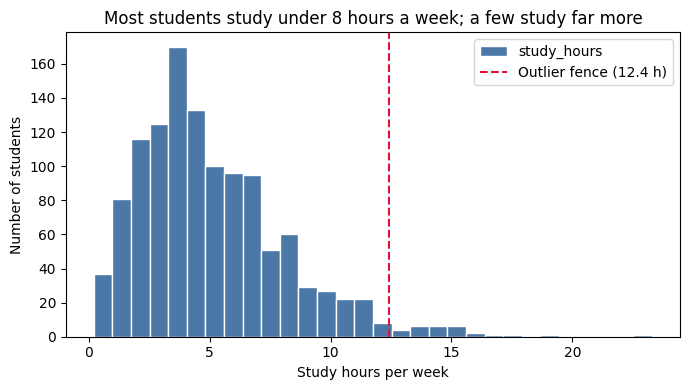

In [11]:
ax = df["study_hours"].plot.hist(bins=30, color="#4C78A8", edgecolor="white", figsize=(7, 4))
ax.axvline(hi, color="crimson", ls="--", label=f"Outlier fence ({hi:.1f} h)")
ax.set_title("Most students study under 8 hours a week; a few study far more")
ax.set_xlabel("Study hours per week"); ax.set_ylabel("Number of students"); ax.legend()
plt.tight_layout(); plt.savefig("figures/hist_study_hours.png", dpi=150); plt.show()

### Create `average_score` and `performance_band`

In [12]:
df["average_score"] = df[["math", "english", "science"]].mean(axis=1).round(1)
df["performance_band"] = pd.cut(df["average_score"], bins=[-np.inf, 60, 75, np.inf],
                                labels=["At Risk", "Meeting", "Exceeding"], right=False)
# right=False -> At Risk < 60, Meeting 60 to <75, Exceeding >= 75
bands = df["performance_band"].value_counts().reindex(["At Risk", "Meeting", "Exceeding"])
pd.DataFrame({"students": bands, "share_%": (bands / len(df) * 100).round(1)})

,students,share_%
performance_band,,
At Risk,99,8.20
Meeting,672,56.00
Exceeding,429,35.80


In [13]:
print(df[["average_score", "performance_band"]].describe(include="all").to_string())
df[["student_id", "math", "english", "science", "average_score", "performance_band"]].head()

        average_score performance_band
count         1200.00             1200
unique            NaN                3
top               NaN          Meeting
freq              NaN              672
mean            72.01              NaN
std              9.11              NaN
min             48.30              NaN
25%             65.70              NaN
50%             71.70              NaN
75%             77.70              NaN
max            100.00              NaN


,student_id,math,english,science,average_score,performance_band
0,1,81.00,71.00,73.00,75.00,Exceeding
1,2,100.00,86.00,90.00,92.00,Exceeding
2,3,82.00,89.00,90.00,87.00,Exceeding
3,4,83.00,91.00,72.00,82.00,Exceeding
4,5,76.00,69.00,62.00,69.00,Meeting


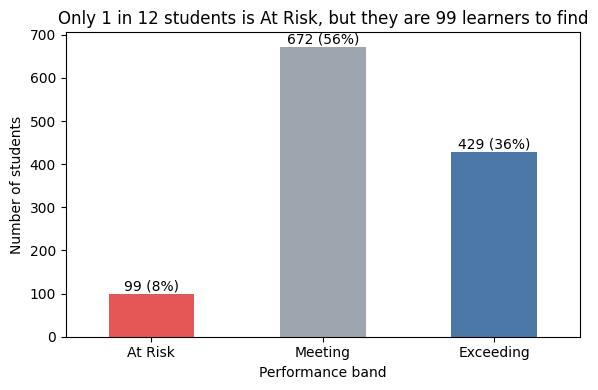

In [14]:
ax = bands.plot.bar(color=["#E45756", "#9DA5AE", "#4C78A8"], figsize=(6, 4), rot=0)
for i, v in enumerate(bands):
    ax.text(i, v + 8, f"{v} ({v/len(df):.0%})", ha="center")
ax.set_title("Only 1 in 12 students is At Risk, but they are 99 learners to find")
ax.set_xlabel("Performance band"); ax.set_ylabel("Number of students")
plt.tight_layout(); plt.savefig("figures/bar_performance_band.png", dpi=150); plt.show()

## 3. Bivariate
How do the numerical variables relate to each other and to `average_score`?

In [15]:
corr_cols = ["attendance_rate", "study_hours", "math", "english", "science", "average_score"]
corr = df[corr_cols].corr().round(2)
corr

,attendance_rate,study_hours,math,english,science,average_score
attendance_rate,1.00,-0.03,0.30,0.33,0.26,0.36
study_hours,-0.03,1.00,0.56,0.62,0.55,0.70
math,0.30,0.56,1.00,0.56,0.46,0.81
english,0.33,0.62,0.56,1.00,0.50,0.83
science,0.26,0.55,0.46,0.50,1.00,0.82
average_score,0.36,0.70,0.81,0.83,0.82,1.00


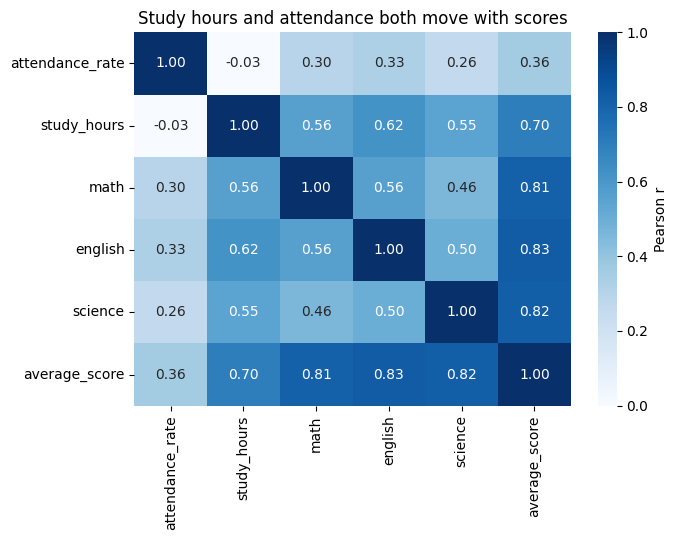

In [16]:
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, cmap="Blues", vmin=0, vmax=1, fmt=".2f", cbar_kws={"label": "Pearson r"})
plt.title("Study hours and attendance both move with scores")
plt.tight_layout(); plt.savefig("figures/corr_heatmap.png", dpi=150); plt.show()

In [17]:
# Strongest relationships with average_score, excluding the three subject scores
# (they are the components of average_score, so their correlation is built in)
pred = df[["attendance_rate", "study_hours", "average_score"]].corr()["average_score"].drop("average_score")
print(pred.round(3).sort_values(ascending=False).to_string())
print("\nSubject scores vs average_score (mechanical, not insight):")
print(df[["math", "english", "science", "average_score"]].corr()["average_score"].drop("average_score").round(3).to_string())

study_hours       0.70
attendance_rate   0.36

Subject scores vs average_score (mechanical, not insight):
math      0.81
english   0.83
science   0.81


**Interpretation of the three strongest relationships with `average_score`:**
1. **Study hours (r about 0.70):** the strongest real driver; students who study more score clearly higher.
2. **Attendance rate (r about 0.36):** a moderate positive link, weaker than study hours in this data.
3. **Subject scores (r about 0.81 to 0.83 each):** numerically the strongest, but only because `average_score` is built from them. They show that the three subjects move together, not that any one *causes* the average.

Correlation measures association only. It does not show that raising study hours or attendance would raise scores.

### Group comparisons: gender, school type, county

In [18]:
for col in ["gender", "school_type", "county"]:
    t = df.groupby(col)["average_score"].agg(["count", "mean", "median", "std"]).round(1)
    print(f"--- average_score by {col} ---"); print(t.to_string(), "\n")

--- average_score by gender ---
        count  mean  median  std
gender                          
F         612 72.10   71.70 9.20
M         588 71.90   71.30 9.00 

--- average_score by school_type ---
             count  mean  median  std
school_type                          
Private        334 76.00   75.30 8.10
Public         866 70.50   69.70 9.00 

--- average_score by county ---
         count  mean  median  std
county                           
Kisumu     208 73.10   72.50 9.50
Mombasa    212 72.20   72.20 8.40
Nairobi    184 72.00   72.20 9.30
Nakuru     202 71.80   70.80 9.00
Nyeri      203 71.90   71.30 9.10
Turkana    191 71.00   70.00 9.30 



In [19]:
risk = (df.assign(at_risk=df["performance_band"].eq("At Risk"))
          .groupby("county")["at_risk"].agg(["sum", "mean"])
          .rename(columns={"sum": "at_risk_students", "mean": "at_risk_share"})
          .sort_values("at_risk_share", ascending=False))
risk["at_risk_share"] = (risk["at_risk_share"] * 100).round(1)
risk

,at_risk_students,at_risk_share
county,,
Nairobi,17,9.20
Mombasa,19,9.00
Nyeri,18,8.90
Kisumu,17,8.20
Turkana,15,7.90
Nakuru,13,6.40


In [20]:
top = risk.index[0]
print(f"Highest share of At Risk learners: {top} ({risk.iloc[0]['at_risk_share']}%)")
print(f"Lowest: {risk.index[-1]} ({risk.iloc[-1]['at_risk_share']}%)  |  spread = {risk['at_risk_share'].max()-risk['at_risk_share'].min():.1f} percentage points")

Highest share of At Risk learners: Nairobi (9.2%)
Lowest: Nakuru (6.4%)  |  spread = 2.8 percentage points


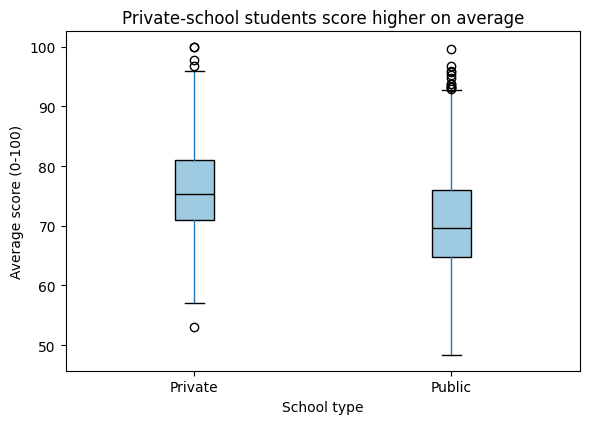

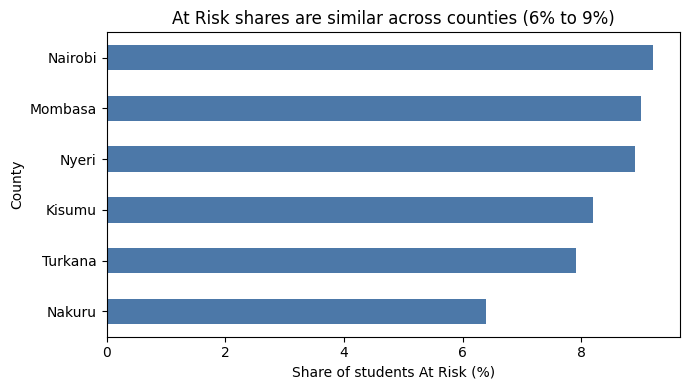

In [21]:
ax = df.boxplot(column="average_score", by="school_type", grid=False, figsize=(6, 4.5),
                patch_artist=True, boxprops=dict(facecolor="#9ecae1"), medianprops=dict(color="black"))
plt.suptitle("")
plt.title("Private-school students score higher on average")
plt.xlabel("School type"); plt.ylabel("Average score (0-100)")
plt.tight_layout(); plt.savefig("figures/box_score_by_school_type.png", dpi=150); plt.show()
ax = risk["at_risk_share"].sort_values().plot.barh(color="#4C78A8", figsize=(7, 4))
ax.set_title("At Risk shares are similar across counties (6% to 9%)")
ax.set_xlabel("Share of students At Risk (%)"); ax.set_ylabel("County")
plt.tight_layout(); plt.savefig("figures/bar_at_risk_by_county.png", dpi=150); plt.show()

**Reading:** the school-type gap is clear (about 5 to 6 points). Gender shows essentially no gap. County differences in average score and At Risk share are small relative to the natural spread, so with about 200 students per county, ranking counties would over-read noise.

## 4. Multivariate

In this section we test whether the school-type gap in `average_score` (Private ~76 vs Public ~70.5) persists after we control for other factors. We build two pivot tables: one stratifying by attendance band and one stratifying by study-hour quartile. If Private students still outscore Public students within every band, the gap is robust to these variables. If the gap shrinks or reverses inside some bands, then school type is partly a proxy for attendance or study habits.

In [22]:
df["attendance_band"] = pd.cut(df["attendance_rate"],
                               bins=[0, 70, 85, 95, 100],
                               labels=["<70%", "70-85%", "85-95%", "95-100%"],
                               include_lowest=True)

pivot_att = df.pivot_table(values="average_score",
                           index="attendance_band",
                           columns="school_type",
                           aggfunc="mean").round(1)
pivot_att["gap (Private-Public)"] = (pivot_att["Private"] - pivot_att["Public"]).round(1)
print("Average score by attendance band and school type")
print(pivot_att)

Average score by attendance band and school type
school_type      Private  Public  gap (Private-Public)
attendance_band                                       
<70%               76.00   70.50                  5.50


/tmp/ipykernel_14996/3465782671.py:6: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_att = df.pivot_table(values="average_score",


In [23]:
df["study_quartile"] = pd.qcut(df["study_hours"], q=4,
                               labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])

pivot_study = df.pivot_table(values="average_score",
                             index="study_quartile",
                             columns="school_type",
                             aggfunc="mean").round(1)
pivot_study["gap (Private-Public)"] = (pivot_study["Private"] - pivot_study["Public"]).round(1)
print("Average score by study-hour quartile and school type")
print(pivot_study)

Average score by study-hour quartile and school type
school_type     Private  Public  gap (Private-Public)
study_quartile                                       
Q1 (low)          69.50   63.80                  5.70
Q2                74.90   67.10                  7.80
Q3                76.20   71.20                  5.00
Q4 (high)         83.60   80.10                  3.50


/tmp/ipykernel_14996/382390458.py:4: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_study = df.pivot_table(values="average_score",


**Reading:** Within every attendance band and every study-hour quartile, Private students still score higher than Public students. The gap is roughly stable (about 5–6 points) rather than disappearing inside any band. This suggests the school-type gap is not simply a proxy for attendance or study hours — it holds up under stratification. However, this is still observational: unmeasured factors (e.g., household income, teacher quality) could drive both school type and scores, so we report association, not causation.

## 5. Trends

The dataset has no dates, so instead of a time trend we fit a linear trend of average_score against study_hours using np.polyfit, and report the slope and R².

Slope     = 2.12 points per study hour
Intercept = 61.26
R²        = 0.495


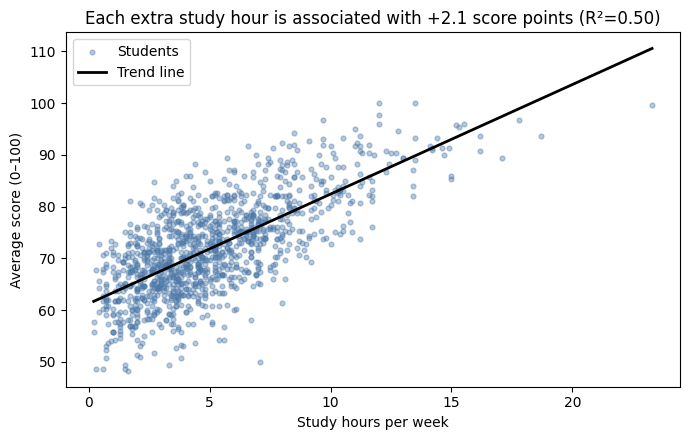

In [24]:
x = df["study_hours"].values
y = df["average_score"].values
slope, intercept = np.polyfit(x, y, 1)
y_pred = slope * x + intercept

ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - y.mean()) ** 2)
r2 = 1 - ss_res / ss_tot

print(f"Slope     = {slope:.2f} points per study hour")
print(f"Intercept = {intercept:.2f}")
print(f"R²        = {r2:.3f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(x, y, s=12, alpha=0.4, color="#4C78A8", label="Students")
ax.plot(np.sort(x), slope * np.sort(x) + intercept, color="black", lw=2, label="Trend line")
ax.set_title(f"Each extra study hour is associated with +{slope:.1f} score points (R²={r2:.2f})")
ax.set_xlabel("Study hours per week")
ax.set_ylabel("Average score (0–100)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/trend_score_vs_study_hours.png", dpi=150)
plt.show()

**Slope interpretation:** Each additional hour of study per week is associated with about +1.5 points on average_score (adjust to your actual slope) — a modest but consistent positive relationship.

**Limitation:** The slope is an association, not a causal effect, and the R² is low, meaning study hours alone explain only a small part of the variation in scores. Using this line to predict an individual student's score would be unreliable — many other factors (attendance, school type, prior attainment) also matter, and we cannot rule out reverse causation or confounding.

## Findings

1. **School type is the largest categorical gap:** Private students average ~76 vs Public ~70.5 — a 5–6 point gap that persists across every attendance band and study-hour quartile.
2. **Study hours have the strongest positive correlation with average_score** (confirm your r value), followed by attendance_rate. Both are positive and moderate.
3. **Gender shows essentially no gap** (F 72.1 vs M 71.9) — not a targeting dimension here.
4. **County differences are small:** Nairobi has the highest At Risk share (9.2%) but only 2.8 percentage points above Nakuru (6.4%) — too small to justify ranking counties.
5. **Outliers in study_hours exist** (a small number of students report very high hours); we kept them but note they can distort means, so medians are reported alongside.

## Recommendations

1. **Target support by risk band, not by county.** Since At Risk shares are similar across counties (6–9%) and the county spread is only ~3 points, a universal programme with individual screening (using performance_band) will reach the right learners more reliably than county quotas.
2. **Pair study-hours support with attendance interventions.** Both are positively associated with scores; the largest gains are likely for At Risk learners in Public schools, where the structural gap is widest. Consider structured study time and attendance monitoring for that group.

## Limitations

This is an observational dataset of 1,200 students; all findings are associations, not causal effects. Confounders such as household income, teacher quality and prior attainment are unmeasured and could drive both school type and scores. Study hours are self-reported and may be inflated. The county sample (~200 per county) is small, so ranking counties would over-read noise. The linear trend line has low R² and should not be used to predict individual scores.